In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
import cv2

In [2]:
# Exibe uma janela para a seleção de um arquivo
from google.colab import files
arquivo = files.upload()
img_name = next(iter(arquivo))

# Leitura da imagem pelo cv2, convertido para tons de cinza
imagem = cv2.imread(img_name, cv2.IMREAD_GRAYSCALE)

Saving Lenna.png to Lenna.png


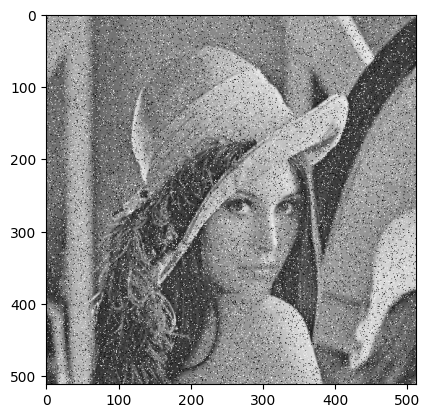

In [4]:

import cv2
import numpy as np
import random

def ruidoSP(imagem, prob):

   saida = imagem.copy()
   limiar = 1 - prob

   for i in range(imagem.shape[0]):
       for j in range(imagem.shape[1]):

            rdn = random.random()
            if rdn < prob:
                saida[i][j] = 0

            elif rdn > limiar:
                saida[i][j] = 255

   return saida

ruidosa = ruidoSP(imagem, 0.05)
plt.imshow(ruidosa,  cmap='gray')

In [5]:
# Criação do kernel de média
mean = np.array(([1, 1, 1],
                 [1, 1, 1],
                 [1, 1, 1]), dtype=float)
# Cada valor da matriz é dividido pela somatoria dos elementos
# Essencialmente, o cálculo da média.
mean = mean / np.sum(mean)
print(mean)

[[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]


In [6]:
# Criação do kernel gaussiano
gaussian = np.array(([1, 2, 1],
                     [2, 4, 2],
                     [1, 2, 1]), dtype=float)
# Cada valor da matriz é dividido pela somatoria dos elementos
gaussian = gaussian / np.sum(gaussian)
print(gaussian)

[[0.0625 0.125  0.0625]
 [0.125  0.25   0.125 ]
 [0.0625 0.125  0.0625]]


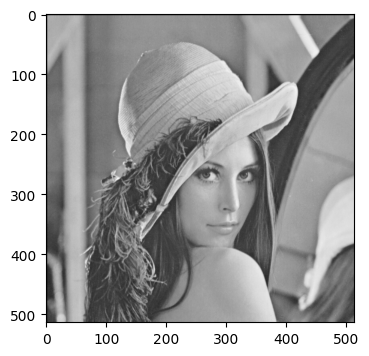

In [7]:
altura, largura = imagem.shape
imagem_padded = np.zeros((altura + 2, largura + 2))

# Copiar a imagem original para o centro
imagem_padded[2:altura + 2, 2:largura + 2] = imagem

plt.figure(figsize=(4,4))
plt.imshow(imagem_padded, cmap='gray')

In [8]:
# Convolução
saida_mean = np.zeros((altura, largura))
saida_gauss = np.zeros((altura, largura))

for i in range(altura):
    for j in range(largura):

        # Extrair a região 3x3
        regiao = imagem_padded[i:i+3, j:j+3]

        # Multiplicação elemento a elemento
        mult_mean = regiao * mean
        mult_gauss = regiao * mean

        # Somar todos os valores
        valor_mean = np.sum(mult_mean)
        valor_gauss = np.sum(mult_gauss)

        # Guardar o resultado
        saida_mean[i, j] = valor_mean
        saida_gauss[i, j] = valor_gauss

saida_mean = saida_mean.astype(np.uint8)
saida_gauss = saida_gauss.astype(np.uint8)


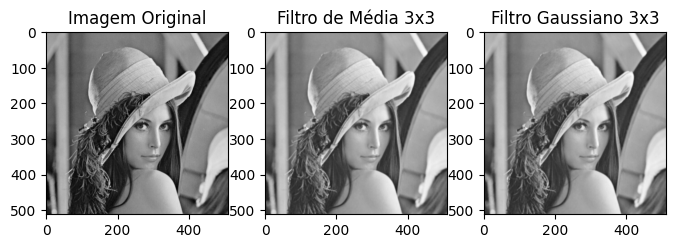

In [12]:
plt.figure(figsize=(8, 5))

plt.subplot(1, 3, 1)
plt.imshow(imagem, cmap='gray')
plt.title('Imagem Original')

plt.subplot(1, 3, 2)
plt.imshow(saida_mean, cmap='gray')
plt.title('Filtro de Média 3x3')

plt.subplot(1, 3, 3)
plt.imshow(saida_gauss, cmap='gray')
plt.title('Filtro Gaussiano 3x3')

plt.show()